# Create a DEG list using propeller of the primary vs metastic tumours in the data from NR Atlas
## Looking at all the DCs here first

Performing DEG analysis (limma, R) on all cancer data from the NR_atlas all DC data. Using code from NR's 2025-01-13-Pseudo_Cancer_DEGS.ipynb and the propeller tutorial https://phipsonlab.github.io/propeller-paper-analysis/pbmcJP.html

Date: 13.04.2026

In [1]:
### install packages required

library(Seurat)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.5; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t




In [2]:
library(sceasy)
library(reticulate)
use_condaenv('R_env')

Loading required package: reticulate



In [3]:
install.packages("edgeR")

Warning message:
“package ‘edgeR’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


In [12]:
if (!require("BiocManager", quietly = TRUE))
    install.packages("BiocManager")
BiocManager::install("speckle")

Bioconductor version '3.20' is out-of-date; the current release version '3.22'
  is available with R version '4.5'; see https://bioconductor.org/install

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.20 (BiocManager 1.30.27), R 4.4.3 (2025-02-28)

Installing package(s) 'speckle'

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Old packages: 'backports', 'cli', 'cpp11', 'dplyr', 'ellipsis', 'fs', 'furrr',
  'hardhat', 'igraph', 'lava', 'lazyeval', 'limma', 'lobstr', 'magrittr',
  'nlme', 'pkgload', 'processx', 'progressr', 'ps', 'purrr', 'ragg', 'recipes',
  'reticulate', 'rlang', 'rmarkdown', 'rpart', 'SeuratObject', 'sourcetools',
  'spatstat.explore', 'spatstat.geom', 'spatstat.random', 'terra',
  'textshaping', 'tinytex', 'vctrs', 'vroom'



In [ ]:

install.packages("patchwork")
install.packages("gridGraphics")

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [13]:
library(limma)
library(edgeR)
library(dplyr)
library(ggplot2)
library(ggrepel)
library(speckle)
library(patchwork)
library(cowplot)
library(gridGraphics)

## Convert anndata object to seurat object

In [5]:
#Set working directory
getwd()
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/R_Jupyter_Analysis")

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code"

In [6]:
data <- '/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad' #this dataset has all the cancer atlas, DC data and primary and metastatic info

In [7]:
head(data)

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad"

In [8]:
sceasy::convertFormat(data, from="anndata", to="seurat", outFile='/scratch/user/uqlbukat/NRAtlas_analysis_2026/AllDC_bbknndata.RDS')

X -> counts



An object of class Seurat 
1746 features across 29887 samples within 1 assay 
Active assay: RNA (1746 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

# Read in converted data

In [14]:
data <- readRDS('/scratch/user/uqlbukat/NRAtlas_analysis_2026/AllDC_bbknndata.RDS')

Explore the data structure

In [10]:
head(data)

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143,2659,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15629172,0.28721189,0.462408497,0.36365491
GSE215120_AM1_ACACTGATCCACTGGG-1,18333,2845,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.18922702,0.26297257,0.329305354,0.54009108
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581,2182,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.13527090,0.03988112,0.149324713,0.03211458
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015,1488,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.36721915,-0.12373999,0.004747235,0.27328160
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642,4010,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.32900991,-0.25416563,0.017663713,0.11923450
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833,2074,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.14672113,0.08149318,0.174721746,-0.17654256
GSE215120_AM1_ACTGAGTCAGGCTGAA-1,7117,1505,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,3.259800,skin,primary tumour,Acral Melanoma,⋯,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15998438,-0.05433711,-0.048045593,0.74123969
GSE215120_AM1_ACTGTCCGTCTCTTAT-1,7875,1515,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.930159,skin,primary tumour,Acral Melanoma,⋯,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15336146,-0.02565772,0.004267385,0.53398699
GSE215120_AM1_ACTTGTTTCTGAAAGA-1,7887,1846,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.738684,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.05677931,0.42842232,0.365930736,-0.08318085


In [11]:
class(data)

[1] "Seurat"
attr(,"package")
[1] "SeuratObject"

In [12]:
#Basic Structure
slotNames(data)

[1] "assays"       "meta.data"    "active.assay" "active.ident" "graphs"      
 [6] "neighbors"    "reductions"   "images"       "project.name" "misc"        
[11] "version"      "commands"     "tools"

In [13]:
#Metadata and cells
colnames(data)           # cell IDs
head(colnames(data))
head(data@meta.data)

[1] "GSE215120_AM1_AAATGCCCAGAGCCAA-1"                                                  
    [2] "GSE215120_AM1_ACACTGATCCACTGGG-1"                                                  
    [3] "GSE215120_AM1_ACAGCCGCAAACCTAC-1"                                                  
    [4] "GSE215120_AM1_ACCAGTAAGACTGGGT-1"                                                  
    [5] "GSE215120_AM1_ACGTCAACAAGGACTG-1"                                                  
    [6] "GSE215120_AM1_ACGTCAATCCGCATCT-1"                                                  
    [7] "GSE215120_AM1_ACTGAGTCAGGCTGAA-1"                                                  
    [8] "GSE215120_AM1_ACTGTCCGTCTCTTAT-1"                                                  
    [9] "GSE215120_AM1_ACTTGTTTCTGAAAGA-1"                                                  
   [10] "GSE215120_AM1_AGAGCTTGTACAGTTC-1"                                                  
   [11] "GSE215120_AM1_AGGGATGGTTTGTGTG-1"                                                  
   [12] "GSE215120_AM1_AGGTCATAGTACGCGA-1"                                                  
   [13] "GSE215120_AM1_AGGTCCGCATTCTTAC-1"                                                  
   [14] "GSE215120_AM1_ATAACGCGTAGCGCTC-1"                                                  
   [15] "GSE215120_AM1_ATAGACCCATTACCTT-1"                                                  
   [16] "GSE215120_AM1_ATCCACCCAGACGCTC-1"                                                  
   [17] "GSE215120_AM1_ATTGGTGAGTCTCGGC-1"                                                  
   [18] "GSE215120_AM1_CACTCCACACTAGTAC-1"                                                  
   [19] "GSE215120_AM1_CAGAGAGTCTTCATGT-1"                                                  
   [20] "GSE215120_AM1_CAGCATAGTGCGGTAA-1"                                                  
   [21] "GSE215120_AM1_CAGCATATCTGCCAGG-1"                                                  
   [22] "GSE215120_AM1_CAGCGACTCTCAACTT-1"                                                  
   [23] "GSE215120_AM1_CATGCCTGTTGGTTTG-1"                                                  
   [24] "GSE215120_AM1_CCATGTCCACCGCTAG-1"                                                  
   [25] "GSE215120_AM1_CCCTCCTGTCCAGTGC-1"                                                  
   [26] "GSE215120_AM1_CCGGGATTCAACACAC-1"                                                  
   [27] "GSE215120_AM1_CGAGCCATCCGAATGT-1"                                                  
   [28] "GSE215120_AM1_CGTCAGGAGGAGTACC-1"                                                  
   [29] "GSE215120_AM1_CGTGTAAGTTCGCTAA-1"                                                  
   [30] "GSE215120_AM1_CTAGTGAGTAGCACGA-1"                                                  
   [31] "GSE215120_AM1_CTAGTGATCACCCGAG-1"                                                  
   [32] "GSE215120_AM1_CTGCCTACAGCTGTTA-1"                                                  
   [33] "GSE215120_AM1_CTGCCTAGTTAAGTAG-1"                                                  
   [34] "GSE215120_AM1_CTGCTGTGTCGTCTTC-1"                                                  
   [35] "GSE215120_AM1_CTGTGCTAGTCGTACT-1"                                                  
   [36] "GSE215120_AM1_GACGGCTCACAAGTAA-1"                                                  
   [37] "GSE215120_AM1_GCAGTTATCATGTCCC-1"                                                  
   [38] "GSE215120_AM1_GCGAGAACACATAACC-1"                                                  
   [39] "GSE215120_AM1_GCGCAACTCGTAGGTT-1"                                                  
   [40] "GSE215120_AM1_GCGCAGTGTAACGACG-1"                                                  
   [41] "GSE215120_AM1_GCGCCAAAGAGAACAG-1"                                                  
   [42] "GSE215120_AM1_GCGCCAACAAGTAATG-1"                                                  
   [43] "GSE215120_AM1_GCGGGTTAGACTAGAT-1"                                                  
   [4

[1] "GSE215120_AM1_AAATGCCCAGAGCCAA-1" "GSE215120_AM1_ACACTGATCCACTGGG-1"
[3] "GSE215120_AM1_ACAGCCGCAAACCTAC-1" "GSE215120_AM1_ACCAGTAAGACTGGGT-1"
[5] "GSE215120_AM1_ACGTCAACAAGGACTG-1" "GSE215120_AM1_ACGTCAATCCGCATCT-1"

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143,2659,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1562917,0.28721189,0.462408497,0.36365491
GSE215120_AM1_ACACTGATCCACTGGG-1,18333,2845,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1892270,0.26297257,0.329305354,0.54009108
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581,2182,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1352709,0.03988112,0.149324713,0.03211458
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015,1488,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.3672192,-0.12373999,0.004747235,0.27328160
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642,4010,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.3290099,-0.25416563,0.017663713,0.11923450
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833,2074,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1467211,0.08149318,0.174721746,-0.17654256


In [14]:
#Check cancer type in object
unique(data@meta.data$cancer_type)

[1] Acral Melanoma        Cutaneous Melanoma    TNBC                 
 [4] HNSCC                 LUAD                  Healthy              
 [7] LUSC                  HER2 Breast Cancer    ER Breast Cancer     
[10] melanoma brain mets   HGSOC                 DCIS                 
[13] IDC                   ER breast cancer      BRCA1 TNBC           
[16] ER breast cancer mets HER2 breast cancer    PDAC                 
[19] CRC                   CRC - Healthy         breast cancer        
[22] Glioblastoma          Metastatic Melanoma   GAC liver mets       
[25] GAC ovarian mets      GAC primary           PDAC Liver mets      
[28] PDAC Lung mets        PDAC primary          CRC mets             
[31] HCC                   PC                    GBM                  
[34] iCCA                  healthy               NSCLC                
[37] NPC                   Diffuse-type GC Sup   Diffuse-type GC Deep 
39 Levels: Acral Melanoma BRCA1 TNBC CRC CRC - Healthy ... melanoma brain mets

In [15]:
#Check sample types (primary or met)
unique(data@meta.data$sample_type_major)
unique(data@meta.data$sample_type_major2)

[1] primary tumour    metastatic tumour local recurrence  healthy          
[5] ascites          
5 Levels: ascites healthy local recurrence ... primary tumour

[1] primary tumour    metastatic tumour healthy           ascites          
Levels: ascites healthy metastatic tumour primary tumour

In [16]:
table(data@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
             3513              3364              5674             17336 

In [17]:
#Assays and features
Assays(data)             # list assays
DefaultAssay(data)
rownames(data)           # gene names

[1] "RNA"

[1] "RNA"

[1] "KLHL17"     "HES4"       "ISG15"      "TNFRSF18"   "TNFRSF4"   
   [6] "MORN1"      "ACOT7"      "ERRFI1"     "SLC2A5"     "GPR157"    
  [11] "FBXO2"      "AGTRAP"     "PDPN"       "PRDM2"      "EPHA2"     
  [16] "PADI2"      "NBL1"       "HSPG2"      "C1QA"       "C1QC"      
  [21] "C1QB"       "LUZP1"      "TCEA3"      "ID3"        "FUCA1"     
  [26] "STPG1"      "RUNX3"      "LDLRAP1"    "STMN1"      "SFN"       
  [31] "SLC9A1"     "IFI6"       "SMPDL3B"    "RAB42"      "SDC3"      
  [36] "FABP3"      "SERINC2"    "LCK"        "MARCKSL1"   "FAM229A"   
  [41] "KIAA1522"   "ZC3H12A"    "POU3F1"     "CDC20"      "PTPRF"     
  [46] "MKNK1"      "PDZK1IP1"   "DHCR24"     "DAB1"       "TACSTD2"   
  [51] "JUN"        "NFIA"       "EFCAB7"     "ROR1"       "PDE4B"     
  [56] "GADD45A"    "WLS"        "CTH"        "NEGR1"      "ST6GALNAC3"
  [61] "AK5"        "DNAJB4"     "IFI44L"     "MCOLN2"     "ODF2L"     
  [66] "GBP1"       "GBP2"       "GBP4"       "GBP5"       "CDC7"      
  [71] "CNN3"       "DPYD"       "VCAM1"      "PRMT6"      "KIAA1324"  
  [76] "GSTM3"      "CSF1"       "KCNA3"      "DENND2D"    "MAGI3"     
  [81] "OLFML3"     "BCAS2"      "CD2"        "NBPF15"     "TXNIP"     
  [86] "FMO5"       "BCL9"       "PDE4DIP"    "HIST2H3D"   "HIST2H2AB" 
  [91] "C1orf54"    "ECM1"       "CTSK"       "C1orf56"    "SELENBP1"  
  [96] "CGN"        "TDRKH"      "TCHH"       "S100A9"     "S100A12"   
 [101] "S100A8"     "S100A7"     "S100A6"     "S100A4"     "S100A2"    
 [106] "S100A16"    "S100A14"    "S100A13"    "S100A1"     "RAB13"     
 [111] "ATP8B2"     "EFNA1"      "MUC1"       "RAB25"      "LMNA"      
 [116] "IQGAP3"     "NES"        "CRABP2"     "SH2D2A"     "ETV3"      
 [121] "CD1A"       "CD1C"       "CD1B"       "CD1E"       "PYHIN1"    
 [126] "FCER1A"     "SLAMF6"     "CD84"       "SLAMF1"     "SLAMF7"    
 [131] "LY9"        "USP21"      "FCGR2A"     "HSPA6"      "FCGR3A"    
 [136] "FCGR2B"     "NOS1AP"     "RGS5"       "PBX1"       "CD247"     
 [141] "CREG1"      "TNFSF18"    "TNFSF4"     "RABGAP1L"   "RASAL2"    
 [146] "ABL2"       "XPR1"       "IER5"       "GLUL"       "RGS16"     
 [151] "NPL"        "LAMC1"      "RGL1"       "IVNS1ABP"   "PTGS2"     
 [156] "CFH"        "ASPM"       "MIR181A1HG" "KIF14"      "TNNT2"     
 [161] "LAD1"       "ELF3"       "UBE2T"      "KDM5B"      "CHI3L1"    
 [166] "CHIT1"      "BTG2"       "ZC3H11A"    "ZBED6"      "PPP1R15B"  
 [171] "CDK18"      "SLC41A1"    "IL10"       "PIGR"       "PFKFB2"    
 [176] "YOD1"       "PLXNA2"     "LAMB3"      "G0S2"       "ATF3"      
 [181] "PTPN14"     "CENPF"      "DNAH14"     "ENAH"       "EPHX1"     
 [186] "TMEM63A"    "CDC42BPA"   "ARV1"       "FAM89A"     "TBCE"      
 [191] "GNG4"       "LYST"       "NID1"       "GPR137B"    "EDARADD"   
 [196] "ACTN2"      "KMO"        "AKT3"       "KIF26B"     "SMYD3"     
 [201] "NLRP3"      "ZNF692"     "PGBD2"      "SH3YL1"     "RSAD2"     
 [206] "LINC00299"  "RRM2"       "FAM49A"     "SDC1"       "RHOB"      
 [211] "ADCY3"      "KRTCAP3"    "CCDC121"    "TRMT61B"    "LBH"       
 [216] "CDC42EP3"   "CYP1B1"     "SLC8A1"     "EML4"       "ZFP36L2"   
 [221] "PRKCE"      "EPAS1"      "EPCAM"      "FBXO11"     "SPTBN1"    
 [226] "UGP2"       "PELI1"      "SPRED2"     "MXD1"       "PCYOX1"    
 [231] "CLEC4F"     "CD207"      "MCEE"       "SPR"        "EGR4"      
 [236] "MTHFD2"     "RTKN"       "RETSAT"     "SFTPB"      "GNLY"      
 [241] "ATOH8"      "ST3GAL5"    "CD8A"       "CD8B"       "EIF2AK3"   
 [246] "MAL"        "ANKRD36C"   "ADRA2B"     "ASTL"       "DUSP2"     
 [251] "NCAPH"      "FAHD2B"     "ANKRD36"    "AC159540.1" "ZAP70"     
 [256] "TMEM131"    "AFF3"       "PDCL3"      "TBC1D8"     "MAP4K4"    
 [261] "IL1R2"      "IL1R1"      "RANBP2"     "MERTK"      "SLC20A1"   
 [266] "CKAP2L"     "IL1A"       "IL1B"       "IL1RN"      "MARCO"     
 [271] "STEAP3"     "EPB41L5"    "NCKAP5"     "MGAT5"      "TMEM163"   
 [276] "ZRANB3"     "CXCR4"      "KYNU"    

In [18]:
# Check counts and normalized data
data[1:5, 1:5]           # small slice
GetAssayData(data, layer = "counts")[1:5, 1:5]
GetAssayData(data, layer = "data")[1:5, 1:5]

An object of class Seurat 
5 features across 5 samples within 1 assay 
Active assay: RNA (5 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

5 x 5 sparse Matrix of class "dgCMatrix"
         GSE215120_AM1_AAATGCCCAGAGCCAA-1 GSE215120_AM1_ACACTGATCCACTGGG-1
KLHL17                        -0.06440404                      -0.06569169
HES4                           2.14238723                       3.57810768
ISG15                          0.17844485                       2.03785219
TNFRSF18                       1.34343664                       3.09841588
TNFRSF4                        3.33262038                       2.65246409
         GSE215120_AM1_ACAGCCGCAAACCTAC-1 GSE215120_AM1_ACCAGTAAGACTGGGT-1
KLHL17                         -0.0683830                      -0.06572413
HES4                            4.4948791                      -0.28542355
ISG15                           2.6584123                       0.90408332
TNFRSF18                       -0.2248601                      -0.22687196
TNFRSF4                        -0.2563366                      -0.25268703
         GSE215120_AM1_ACGTCAACAAGGACTG-1
KLHL17           

5 x 5 sparse Matrix of class "dgCMatrix"
         GSE215120_AM1_AAATGCCCAGAGCCAA-1 GSE215120_AM1_ACACTGATCCACTGGG-1
KLHL17                        -0.06440404                      -0.06569169
HES4                           2.14238723                       3.57810768
ISG15                          0.17844485                       2.03785219
TNFRSF18                       1.34343664                       3.09841588
TNFRSF4                        3.33262038                       2.65246409
         GSE215120_AM1_ACAGCCGCAAACCTAC-1 GSE215120_AM1_ACCAGTAAGACTGGGT-1
KLHL17                         -0.0683830                      -0.06572413
HES4                            4.4948791                      -0.28542355
ISG15                           2.6584123                       0.90408332
TNFRSF18                       -0.2248601                      -0.22687196
TNFRSF4                        -0.2563366                      -0.25268703
         GSE215120_AM1_ACGTCAACAAGGACTG-1
KLHL17           

In [19]:
#Check DC types in object
unique(data@meta.data$NR_annotations_simple)

[1] cDC2   cDC1   mregDC
Levels: cDC1 cDC2 mregDC

In [20]:
table(data@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  6670  17166   6051 

Visualise the mreg DC UMAP in the Cancer dataset

In [58]:
#my_colors <- c("cDC1" = "#FF0000", "cDC2" = "#00FF00", "mregDC" = "")

my_cols <- c("mregDC" = "#8C564B", "cDC1" = "#E377C2", "cDC2" = "#AA40FC")

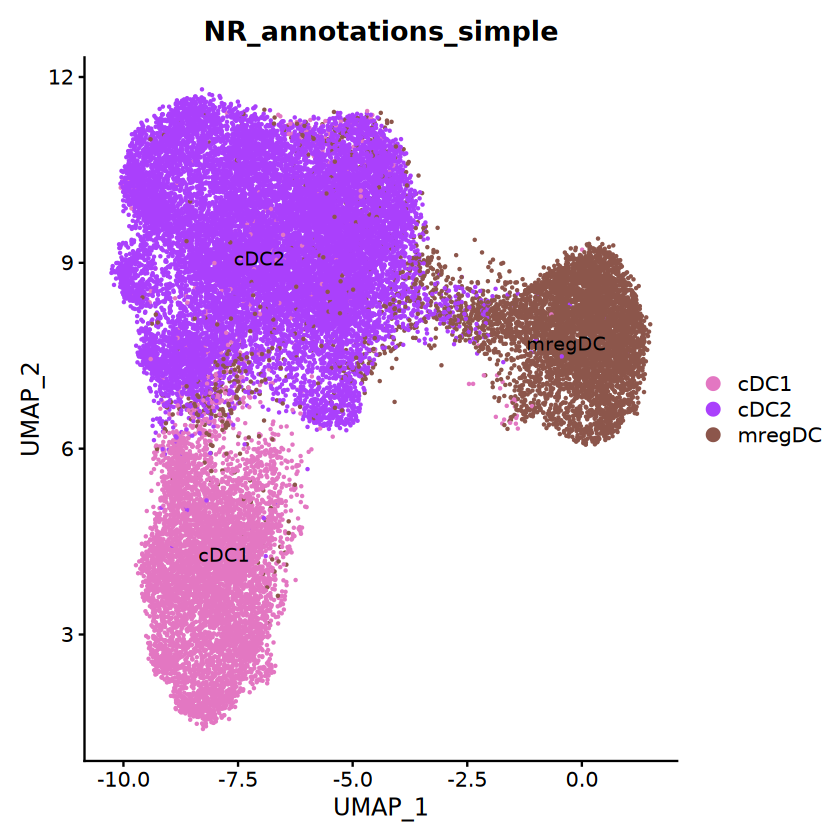

In [59]:
#FeaturePlot(oc.data, features = features)
DimPlot(data, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

# Create a DEG list (primary vs mets) of the mregDCs 

Use the code generated from Perplexity (23.3.26)

In [23]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "mregDC"

data_mregDC <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [24]:
data_mregDC

An object of class Seurat 
1746 features across 6051 samples within 1 assay 
Active assay: RNA (1746 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

In [25]:
#Confirm that our subsetted data only has our cells of interest
table(data_mregDC@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0      0   6051 

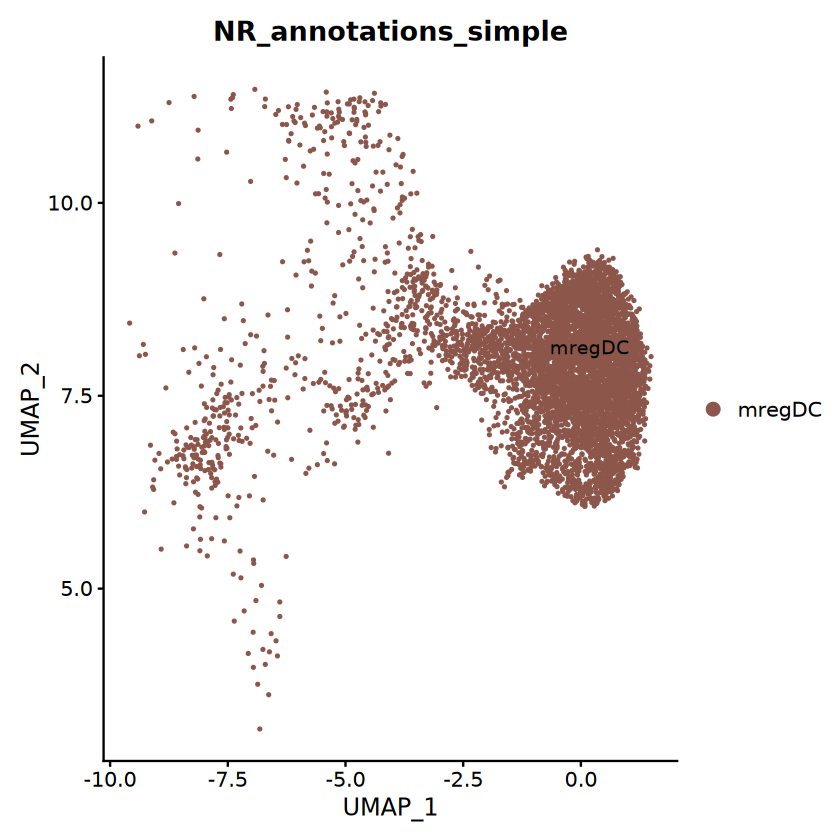

In [60]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_mregDC, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

In [27]:
# Set the cell identities to the "sample" metadata column
Idents(data_mregDC) <- data_mregDC@meta.data$sample_type_major2

# Confirm
table(Idents(data_mregDC))


          ascites           healthy metastatic tumour    primary tumour 
              246               471              1103              4231 

In [28]:
#subset further to only have primary and metastatic data
data_mregDC_sub <- subset(data_mregDC,
subset = sample_type_major2 %in% c("primary tumour", "metastatic tumour"))


In [29]:
table(data_mregDC_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0      0   5334 

In [30]:
# Confirm the counts in the subsetted data
#Set the cell identities to the "sample" metadata column
Idents(data_mregDC_sub) <- data_mregDC_sub@meta.data$sample_type_major2

# Confirm
table(Idents(data_mregDC_sub))


metastatic tumour    primary tumour 
             1103              4231 

In [31]:
#Confirm that our subsetted data only has our states of interest
table(data_mregDC_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0                 0              1103              4231 

Run Differential Expression between two states

In [32]:
# Define which two states to compare
group1 <- "primary tumour"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_mreg <- FindMarkers(
  object = data_mregDC_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777    
)

head(deg_res_mreg)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LGALS1,2.366936e-51,2.198705,0.656,0.444,4.132671e-48
UVRAG,4.144966e-50,-1.674390,0.488,0.704,7.237111e-47
JUND,5.285615e-50,-2.774907,0.295,0.545,9.228684e-47
CCL3,2.240721e-45,2.922782,0.154,0.093,3.912300e-42
SRRM2,6.440553e-44,-1.797316,0.480,0.675,1.124521e-40
HBA1,3.645258e-43,1.754588,0.154,0.101,6.364620e-40


deg_res will be a data frame with columns like:

* p_val

* avg_log2FC (or avg_logFC depending on Seurat version)

* pct.1 and pct.2

* p_val_adj

In [33]:
deg_sig_mreg <- subset(
  deg_res_mreg,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_mreg[order(deg_sig_mreg$avg_log2FC, decreasing = TRUE), ], n = 10)


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
BTBD11,1.837682e-15,3.681193,0.406,0.303,3.208594e-12
DNAH17,6.383459e-26,3.379155,0.119,0.087,1.114552e-22
CYBB,1.474812e-11,3.177528,0.069,0.107,2.575023e-08
CD69,1.174867e-26,2.993725,0.101,0.083,2.051317e-23
CCL3,2.240721e-45,2.922782,0.154,0.093,3.912300e-42
S100A13,4.485328e-10,2.842678,0.118,0.076,7.831383e-07
RAMP1,7.160080e-06,2.487940,0.360,0.192,1.250150e-02
H1F0,5.863015e-08,2.387081,0.144,0.113,1.023682e-04
GPRIN3,5.603847e-13,2.326367,0.072,0.111,9.784317e-10


In [34]:
deg_sig_mreg

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LGALS1,2.366936e-51,2.1987048,0.656,0.444,4.132671e-48
UVRAG,4.144966e-50,-1.6743898,0.488,0.704,7.237111e-47
JUND,5.285615e-50,-2.7749075,0.295,0.545,9.228684e-47
CCL3,2.240721e-45,2.9227816,0.154,0.093,3.912300e-42
SRRM2,6.440553e-44,-1.7973158,0.480,0.675,1.124521e-40
HBA1,3.645258e-43,1.7545884,0.154,0.101,6.364620e-40
FSCN1,2.278522e-36,0.8222930,0.842,0.787,3.978300e-33
ANKRD28,7.817792e-35,2.1962097,0.100,0.083,1.364986e-31
CST7,6.723106e-34,1.3832514,0.645,0.456,1.173854e-30


Quick visualisation

In [35]:
top_genes_mreg <- rownames(head(deg_sig_mreg[order(deg_sig_mreg$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_mreg


[1] "BTBD11"  "DNAH17"  "CYBB"    "CD69"    "CCL3"    "S100A13" "RAMP1"  
 [8] "H1F0"    "GPRIN3"  "LGALS1"

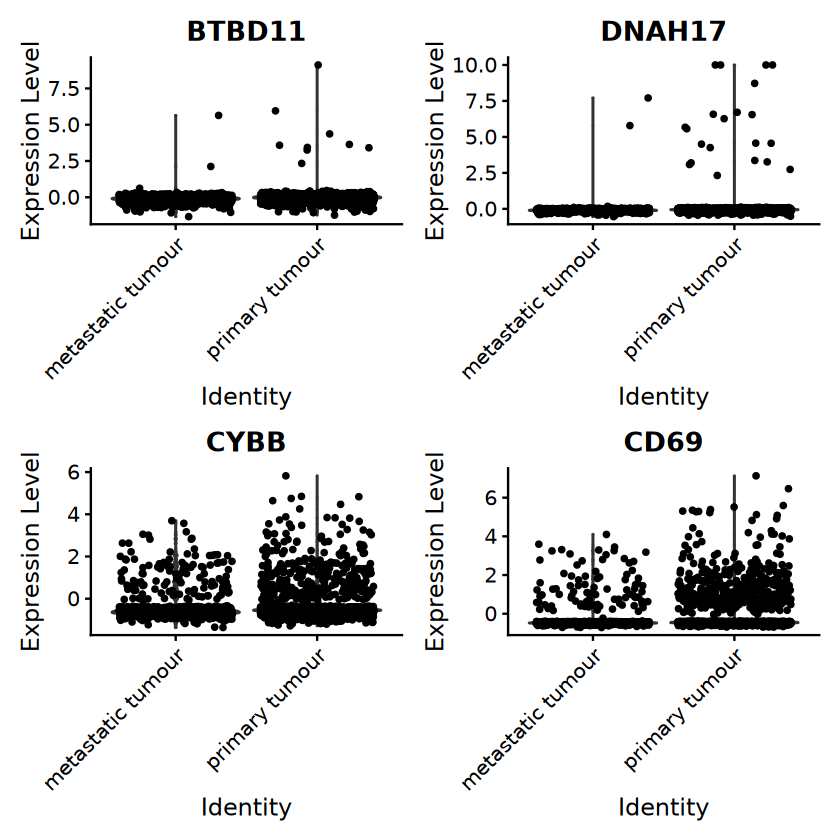

In [36]:
VlnPlot(data_mregDC_sub, features = top_genes_mreg[1:4], group.by = "sample_type_major2", ncol = 2)

In [37]:
p <- FeaturePlot(data_mregDC_sub, features = top_genes_mreg[1:4], split.by = "sample_type_major2")
ggsave("mregDEGfeatureplot.png", p, width = 8, height = 7, dpi = 300)

* BTBD11 -> BTB/POZ domain-containing protein 11 is a gene that encodes a protein, primarily expressed in the brain's cerebral cortex and hippocampus, which is critical for supporting the function of glutamatergic synapses within inhibitory interneurons.
* DNAH17 -> Dynein Axonemal Heavy Chain 17 encodes a protein crucial for the structure and movement of the outer dynein arms (ODAs) in the sperm flagellum.
* CYBB -> located on the X chromosome, encodes the gp91-phox protein, a critical subunit of the NADPH oxidase enzyme complex in phagocytes.
* CD69 -> CD69 encodes a type II transmembrane glycoprotein that acts as one of the earliest cell surface markers for T-lymphocyte activation, often referred to as the early **T-cell activation antigen (EA1)**.

# Create a DEG list (primary vs mets) of the cDC2s

In [38]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "cDC2"

data_cDC2 <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [39]:
#Confirm that our subsetted data only has our cells of interest
table(data_cDC2@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0  17166      0 

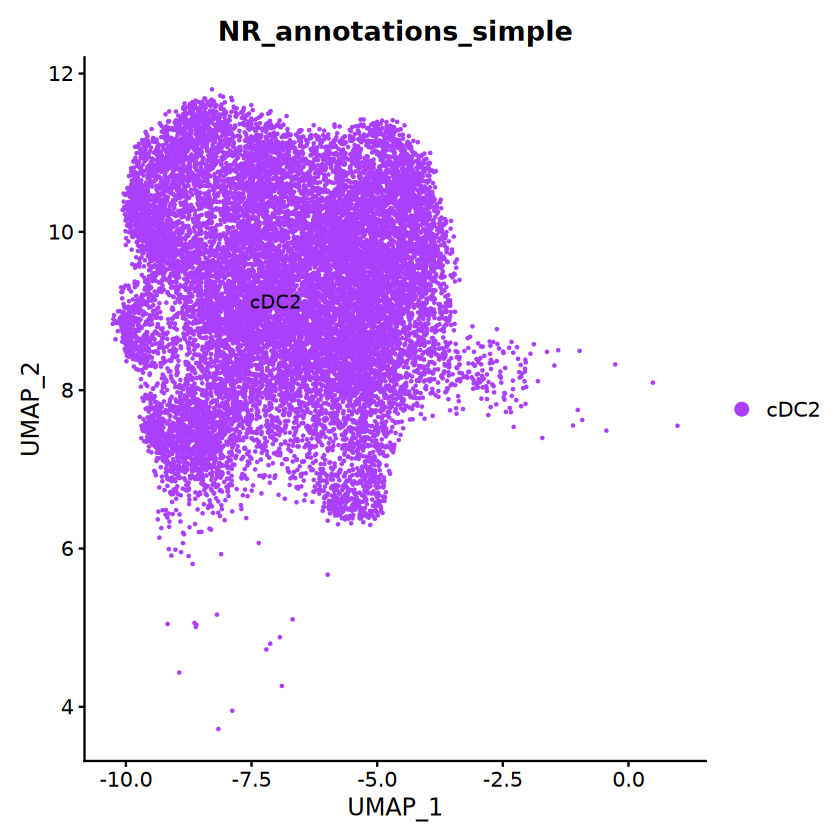

In [61]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_cDC2, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set Identities for the sample column

In [41]:
# Set the cell identities to the "sample" metadata column
Idents(data_cDC2) <- data_cDC2@meta.data$sample_type_major2

# Confirm
table(Idents(data_cDC2))


          ascites           healthy metastatic tumour    primary tumour 
             2242              2188              3172              9564 

In [42]:
#subset further to only have primary and metastatic data
data_cDC2_sub <- subset(data_cDC2,
subset = sample_type_major2 %in% c("primary tumour", "metastatic tumour"))


In [43]:
#Confirm that our subsetted data only has our states of interest
table(data_cDC2_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0                 0              3172              9564 

In [44]:
#confirm our subset counts
table(data_cDC2_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0  12736      0 

Run Differential Expression between two states

In [45]:
# Define which two states to compare
group1 <- "primary tumour"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_dc2 <- FindMarkers(
  object = data_cDC2_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777        
)

head(deg_res_dc2)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
S100A7,2.214376e-138,3.435344,0.058,0.108,3.866301e-135
KRT13,1.182226e-132,3.415239,0.080,0.143,2.064167e-129
LY6D,2.717026e-128,6.425013,0.081,0.153,4.743928e-125
CALML3,4.830459e-125,2.018127,0.080,0.148,8.433982e-122
LMNA,4.622522e-124,2.118402,0.467,0.293,8.070923e-121
ZC3H11A,2.652709e-123,3.384380,0.101,0.048,4.631629e-120


In [62]:
deg_sig_dc2 <- subset(
  deg_res_dc2,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_dc2[order(deg_sig_dc2$avg_log2FC, decreasing = TRUE), ], n = 10)


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LY6D,2.717026e-128,6.425013,0.081,0.153,4.743928e-125
KRT16,3.020605e-119,6.070587,0.057,0.101,5.273976e-116
HBA1,2.589308e-75,5.883995,0.180,0.101,4.520932e-72
RPS17,2.079894e-95,5.060637,0.531,0.295,3.631494e-92
APOA1,1.022361e-10,3.967847,0.086,0.116,1.785042e-07
SFTPB,4.272189e-84,3.857166,0.068,0.102,7.459242e-81
ITGB8,7.353335e-95,3.814298,0.139,0.089,1.283892e-91
HBA2,2.583786e-73,3.734481,0.101,0.060,4.511291e-70
S100A7,2.214376e-138,3.435344,0.058,0.108,3.866301e-135


Quick Visualisation

In [47]:
top_genes_dc2 <- rownames(head(deg_sig_dc2[order(deg_sig_dc2$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_dc2

[1] "LY6D"   "KRT16"  "HBA1"   "RPS17"  "APOA1"  "SFTPB"  "ITGB8"  "HBA2"  
 [9] "S100A7" "KRT13"

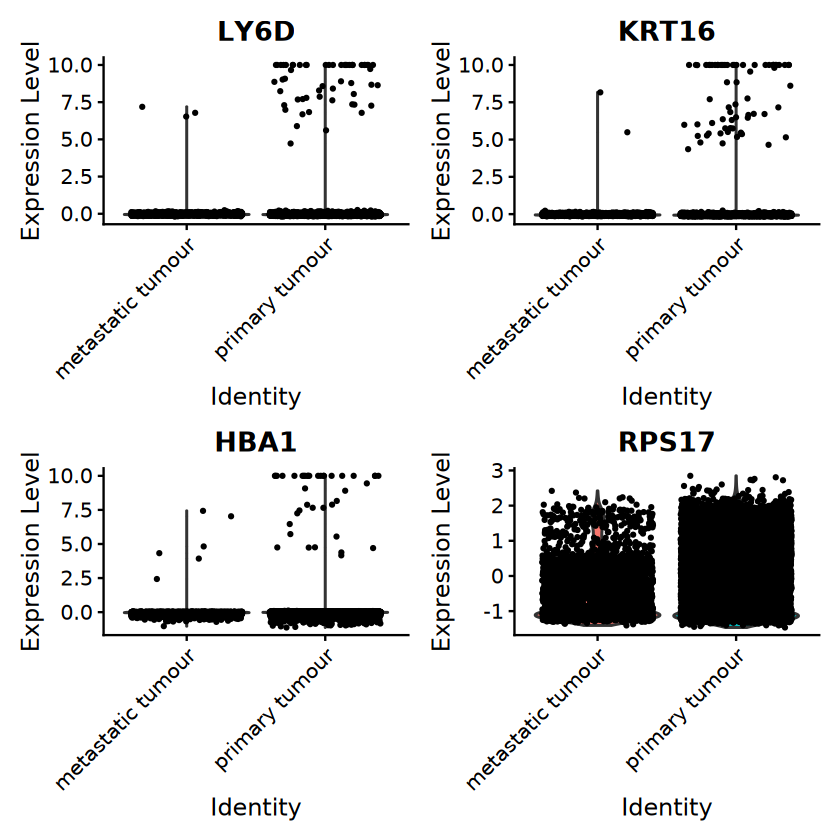

In [64]:
VlnPlot(data_cDC2_sub, features = top_genes_dc2[1:4], group.by = "sample_type_major2", pt.size = 0.5, ncol = 2)

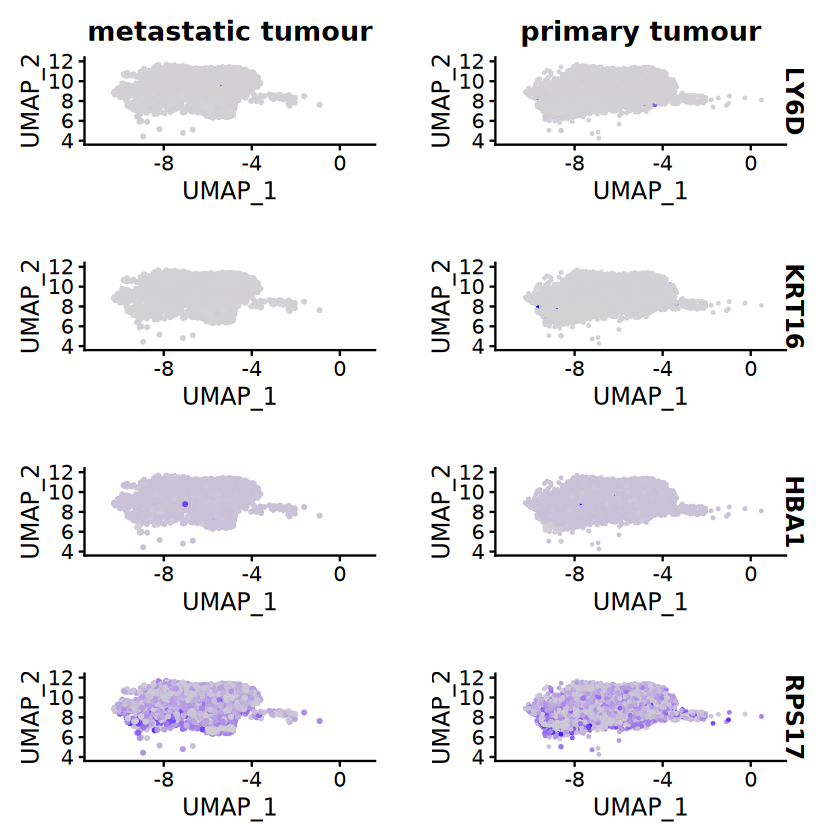

In [49]:
FeaturePlot(data_cDC2_sub, features = top_genes_dc2[1:4], split.by = "sample_type_major2")

* LY6D -> Lymphocyte Antigen 6 Family Member D is a protein-coding gene that encodes a GPI-anchored cell surface protein involved in lymphocyte differentiation and B-cell specification. It acts as a marker for early B-cell development and is highly expressed in various epithelial tissues, including skin, bladder, and esophagus. High LY6D expression is linked to poor prognosis in multiple cancers (prostate, lung, squamous cell carcinoma) and contributes to disease progression. 
* KRT16 -> Keratin 16 encodes a type I intermediate filament protein that provides structural integrity to epithelial cells, particularly in the skin, nails, and oral mucosa
* HBA1 -> Hemoglobin Subunit Alpha 1 is a gene that provides instructions for making alpha-globin, a vital component of hemoglobin, which carries oxygen in red blood cells.
* RPS17 -> Ribosomal Protein S17 encodes a structural component of the 40S ribosomal subunit in humans, playing an essential role in protein biosynthesis (translation).

# Create a DEG list (primary vs mets) of the cDC1s

In [50]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "cDC1"

data_cDC1 <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [51]:
#Confirm that our subsetted data only has our cells of interest
table(data_cDC1@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  6670      0      0 

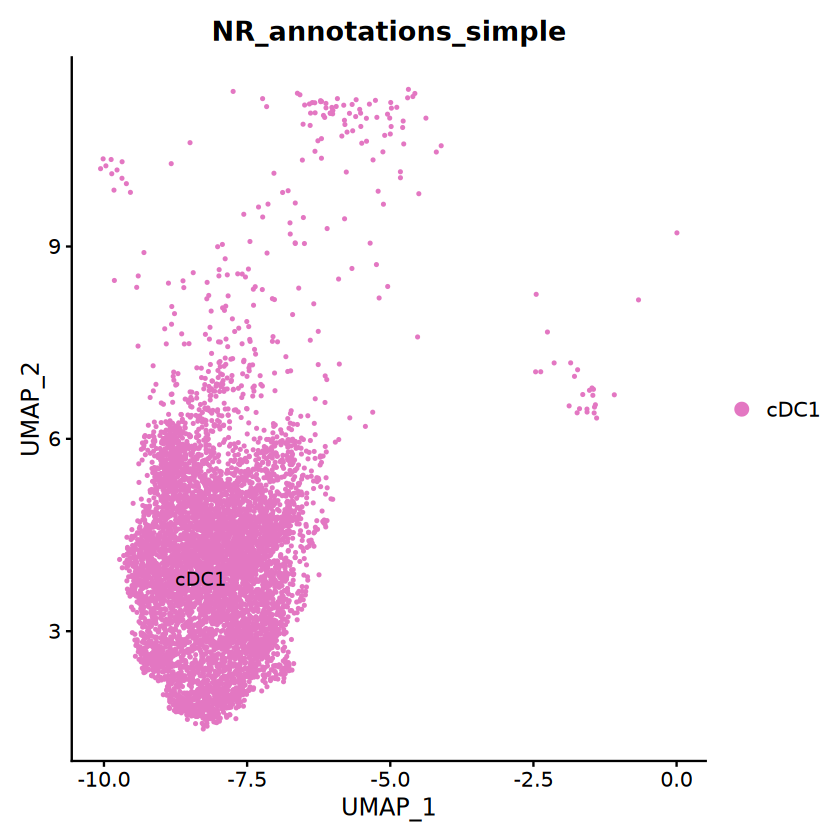

In [65]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_cDC1, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set identities for the sample column

In [53]:
# Set the cell identities to the "sample" metadata column
Idents(data_cDC1) <- data_cDC1@meta.data$sample_type_major2

# Confirm
table(Idents(data_cDC1))


          ascites           healthy metastatic tumour    primary tumour 
             1025               705              1399              3541 

In [54]:
#subset further to only have primary and metastatic data
data_cDC1_sub <- subset(data_cDC1,
subset = sample_type_major2 %in% c("primary tumour", "metastatic tumour"))

In [55]:
#Confirm that our subsetted data only has our states of interest
table(data_cDC1_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0                 0              1399              3541 

In [56]:
#confirm our cell counts
table(data_cDC1_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  4940      0      0 

Run Differential Expression between the states

In [66]:
# Define which two states to compare
group1 <- "primary tumour"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_dc1 <- FindMarkers(
  object = data_cDC1_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777        
)

head(deg_res_dc1)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CLNK,9.298411e-73,-1.3589857,0.509,0.734,1.623503e-69
CADM1,3.184991e-57,-1.6082198,0.533,0.731,5.560994e-54
CD81,7.847604e-54,-1.1278165,0.338,0.561,1.370192e-50
MPEG1,1.051758e-49,-0.9258378,0.595,0.766,1.836370e-46
WDFY4,8.350130e-49,-1.1972937,0.712,0.848,1.457933e-45
CPNE3,1.441080e-48,-0.6193216,0.773,0.892,2.516126e-45


In [67]:
deg_sig_dc1 <- subset(
  deg_res_dc1,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], n = 10)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RHOB,1.145056e-16,10.899949,0.144,0.128,1.999267e-13
SLC34A2,9.913162e-14,9.597514,0.100,0.131,1.730838e-10
CSF1,1.061024e-20,8.074411,0.111,0.066,1.852549e-17
CEACAM6,1.277774e-18,6.319753,0.083,0.121,2.230993e-15
CD9,3.879260e-11,5.543812,0.167,0.137,6.773188e-08
KSR1,1.282377e-20,5.382395,0.117,0.094,2.239030e-17
TWISTNB,5.992108e-16,4.945241,0.127,0.113,1.046222e-12
AHRR,4.198582e-23,4.926811,0.357,0.232,7.330724e-20
MT1X,8.908457e-10,4.670705,0.162,0.148,1.555417e-06


Quick Visualisation

In [69]:
top_genes_dc1 <- rownames(head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_dc1

[1] "RHOB"    "SLC34A2" "CSF1"    "CEACAM6" "CD9"     "KSR1"    "TWISTNB"
 [8] "AHRR"    "MT1X"    "RASA2"

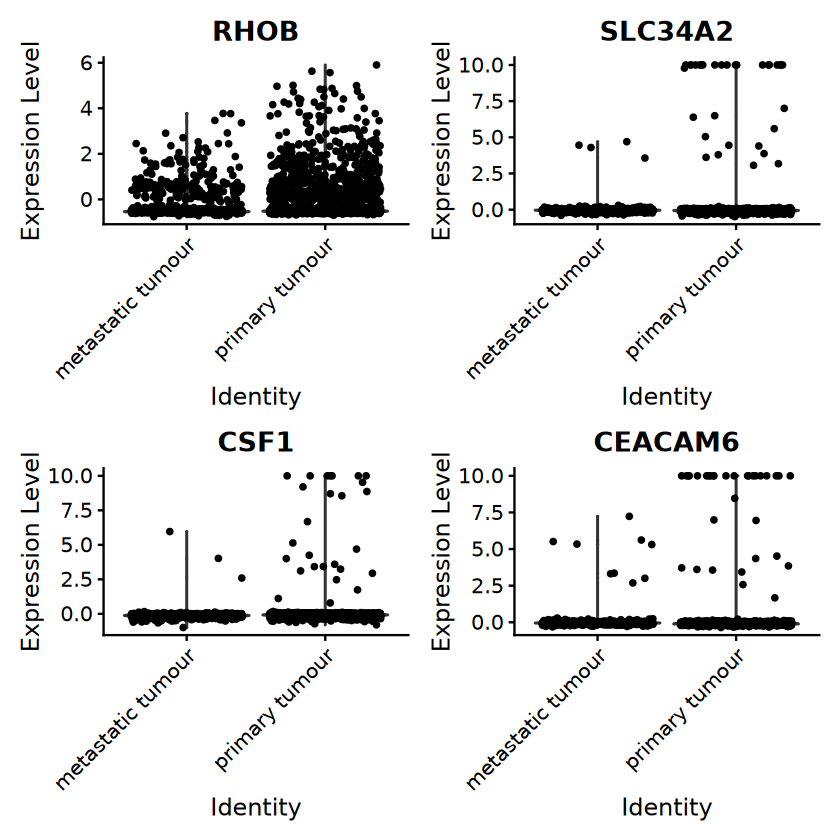

In [70]:
VlnPlot(data_cDC1_sub, features = top_genes_dc1[1:4], group.by = "sample_type_major2", ncol = 2)

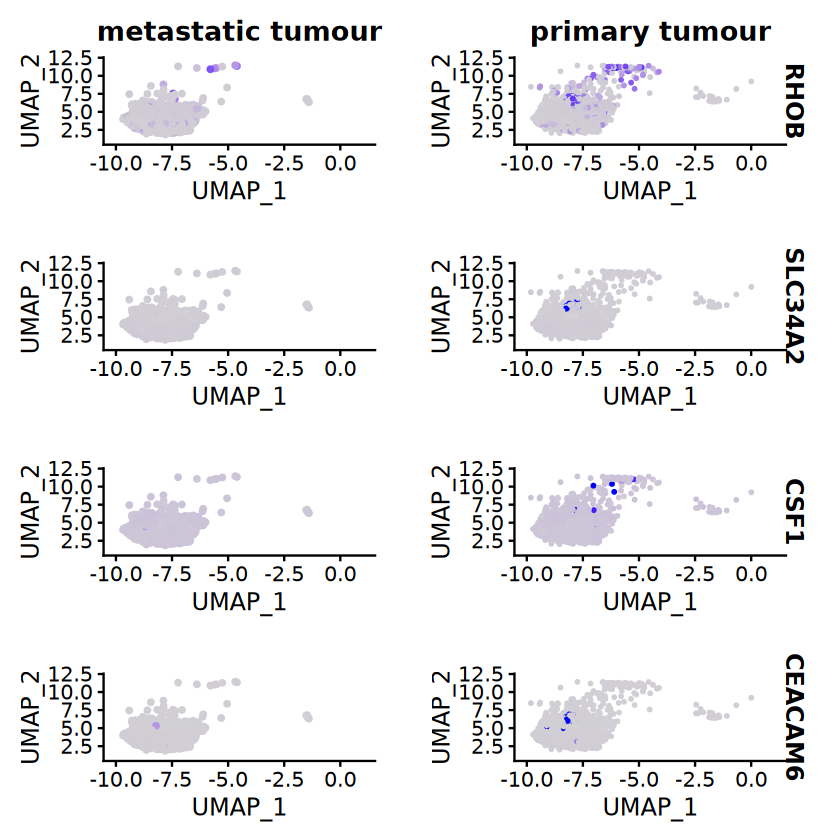

In [71]:
FeaturePlot(data_cDC1_sub, features = top_genes_dc1[1:4], split.by = "sample_type_major2")

* RHOB -> Ras homolog family member B encodes a small GTP-binding protein that acts as a sensor for cellular stress, regulating essential processes like cell survival, apoptosis, membrane trafficking, and cytoskeleton rearrangement.
* SLC34A2 -> Solute Carrier Family 34 Member 2 encodes a sodium-dependent phosphate cotransporter (NaPi-IIb) that maintains phosphate homeostasis, particularly in the lungs and intestine.
* CSF1 -> Colony Stimulating Factor 1 encodes a cytokine, often called M-CSF (Macrophage Colony-Stimulating Factor), that regulates the survival, proliferation, and differentiation of hematopoietic precursor cells, primarily macrophages and monocytes
* CEACAM6 -> Carcinoembryonic Antigen Related Cell Adhesion Molecule 6 encodes a glycosylphosphatidylinositol (GPI)-anchored surface glycoprotein. It is a well-known tumor marker and cell adhesion molecule overexpressed in various cancers, including pancreatic, colorectal, and breast cancer.

# Trying to make a Volcano Plot

In [ ]:
# Find markers for cDC2s
markers <- FindMarkers(object = data_cDC1, ident.1 = "2", min.pct = 0.25)
markers$gene <- rownames(markers)

ERROR: Error in WhichCells.Seurat(object = object, idents = ident.1): Cannot find the following identities in the object: 2


In [ ]:
### Define significance
markers <- markers %>%
  mutate(significance = ifelse(p_val_adj < 0.05 & abs(avg_log2FC) > 1, "Significant", "Not Significant"))


In [ ]:
head(deg_res_mreg)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LGALS1,2.366936e-51,2.198705,0.656,0.444,4.132671e-48
UVRAG,4.144966e-50,-1.674390,0.488,0.704,7.237111e-47
JUND,5.285615e-50,-2.774907,0.295,0.545,9.228684e-47
CCL3,2.240721e-45,2.922782,0.154,0.093,3.912300e-42
SRRM2,6.440553e-44,-1.797316,0.480,0.675,1.124521e-40
HBA1,3.645258e-43,1.754588,0.154,0.101,6.364620e-40


In [ ]:
mreg_vp <- deg_res_mreg %>%
tibble::rownames_to_column("gene")%>%
arrange(p_val_adj, desc(avg_log2FC))

In [ ]:
head(mreg_vp, 10)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LGALS1,2.366936e-51,2.198705,0.656,0.444,4.132671e-48
2,UVRAG,4.144966e-50,-1.674390,0.488,0.704,7.237111e-47
3,JUND,5.285615e-50,-2.774907,0.295,0.545,9.228684e-47
4,CCL3,2.240721e-45,2.922782,0.154,0.093,3.912300e-42
5,SRRM2,6.440553e-44,-1.797316,0.480,0.675,1.124521e-40
6,HBA1,3.645258e-43,1.754588,0.154,0.101,6.364620e-40
7,FSCN1,2.278522e-36,0.822293,0.842,0.787,3.978300e-33
8,ANKRD28,7.817792e-35,2.196210,0.100,0.083,1.364986e-31
9,CST7,6.723106e-34,1.383251,0.645,0.456,1.173854e-30


In [73]:
mreg_vp <- deg_res_mreg%>%
mutate(neglog10_padj = -log10(p_val_adj + 1e-300),
sig = p_val_adj < 0.05 & abs (avg_log2FC) > 0.25
)%>%
tibble::rownames_to_column("gene")

In [74]:
head(mreg_vp)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,neglog10_padj,sig
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,LGALS1,2.366936e-51,2.198705,0.656,0.444,4.132671e-48,47.38377,TRUE
2,UVRAG,4.144966e-50,-1.674390,0.488,0.704,7.237111e-47,46.14043,TRUE
3,JUND,5.285615e-50,-2.774907,0.295,0.545,9.228684e-47,46.03486,TRUE
4,CCL3,2.240721e-45,2.922782,0.154,0.093,3.912300e-42,41.40757,TRUE
5,SRRM2,6.440553e-44,-1.797316,0.480,0.675,1.124521e-40,39.94903,TRUE
6,HBA1,3.645258e-43,1.754588,0.154,0.101,6.364620e-40,39.19623,TRUE


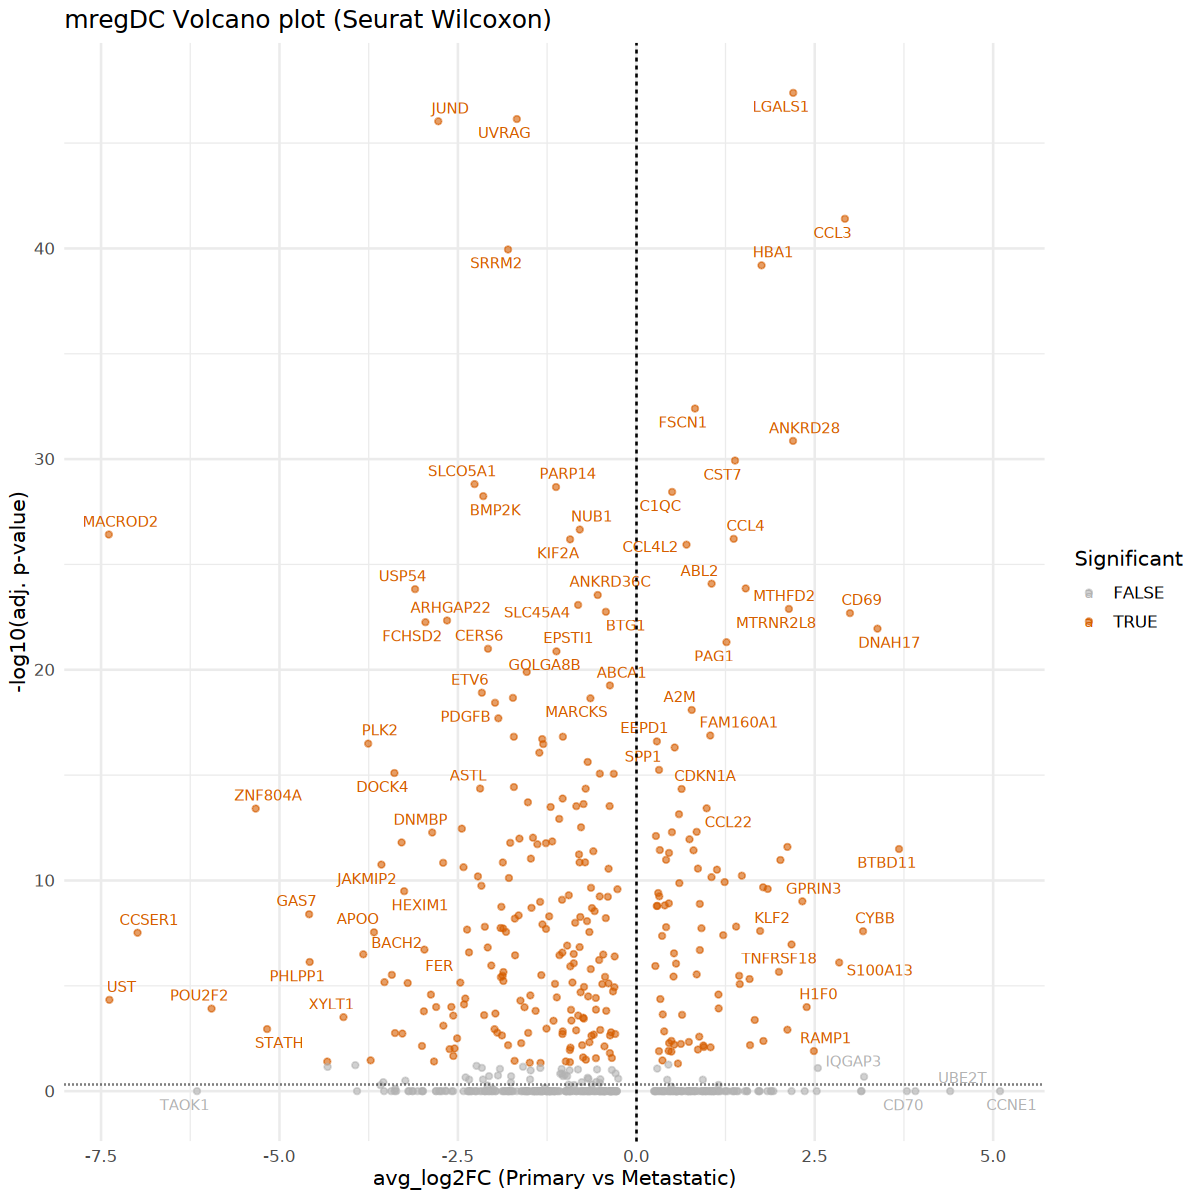

In [77]:

ggplot(mreg_vp, aes(x = avg_log2FC, y = neglog10_padj, color = sig, label = gene)) +
  geom_point(alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  labs(
    title = "mregDC Volcano plot (Seurat Wilcoxon)",
    x = "avg_log2FC (Primary vs Metastatic)",
    y = "-log10(adj. p-value)",
    color = "Significant"
  ) +
  geom_text_repel(size = 3,  max.overlaps = 5) +
  geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  geom_hline(yintercept = c(-log10(0.5)), linetype = "dotted", color = "black") +
  theme_minimal(base_size = 12)

  options(repr.plot.width=10, repr.plot.height=10)
